# Desafio 1 — Análise de Crédito

**Objetivo:** investigar os fatores associados à inadimplência e avaliar se o histórico de propostas permite identificar solicitações de maior risco.

A variável `inadimplente` é binária, portanto o problema é de classificação supervisionada. O modelo principal exigido pelo desafio é a Regressão Logística.

## 1. Configuração e importações

A execução é reprodutível com `RANDOM_STATE = 42`. O notebook usa o arquivo bruto e a mesma rotina de tratamento versionada em `tratamento_dados.py`.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, precision_score,
    recall_score, roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "dataset.csv").exists():
    PROJECT_DIR = PROJECT_DIR / "desafios" / "analise-credito"
sys.path.insert(0, str(PROJECT_DIR))
from tratamento_dados import tratar_dados

print(f"Diretório do projeto: {PROJECT_DIR.resolve()}")

Diretório do projeto: D:\lab\Analise_Credito\desafios\analise-credito


## 2. Carregamento e entendimento do problema

Cada linha representa uma proposta de crédito. A resposta `inadimplente` indica se houve inadimplência após o acompanhamento da proposta. As demais colunas são potenciais variáveis explicativas disponíveis no momento da análise.

In [2]:
bruto = pd.read_csv(PROJECT_DIR / "dataset.csv")
colunas_esperadas = [
    "idade", "estado", "escolaridade", "renda_mensal",
    "tempo_emprego_anos", "score_credito", "valor_solicitado",
    "prazo_meses", "finalidade", "dividas_ativas", "inadimplente",
]
assert list(bruto.columns) == colunas_esperadas
assert set(bruto["inadimplente"].unique()) == {0, 1}
print(f"Dimensões: {bruto.shape[0]:,} linhas x {bruto.shape[1]} colunas")
display(bruto.head())
display(bruto.dtypes.rename("tipo").to_frame())

Dimensões: 5,000 linhas x 11 colunas


,idade,estado,escolaridade,renda_mensal,tempo_emprego_anos,score_credito,valor_solicitado,prazo_meses,finalidade,dividas_ativas,inadimplente
0,52,MS,Ensino Superior,"2,911.820",14,690,"5,934.190",60,Viagem,1,0
1,49,RR,Ensino Médio,"3,176.430",5,676,"6,791.380",24,Outros,2,0
2,48,AL,Ensino Superior,"3,429.400",23,558,"14,666.780",24,Outros,5,1
3,59,GO,Ensino Fundamental,"10,096.700",2,739,"19,053.240",24,Reforma,0,0
4,37,RJ,Ensino Fundamental,"3,033.250",24,797,"6,171.310",6,Educação,0,1


,tipo
idade,int64
estado,str
escolaridade,str
renda_mensal,float64
tempo_emprego_anos,int64
score_credito,int64
valor_solicitado,float64
prazo_meses,int64
finalidade,str
dividas_ativas,int64


### Qualidade dos dados brutos

In [3]:
qualidade_bruta = pd.DataFrame({
    "ausentes": bruto.isna().sum(),
    "valores_distintos": bruto.nunique(),
    "tipo": bruto.dtypes.astype(str),
})
print(f"Duplicatas exatas: {bruto.duplicated().sum()}")
display(qualidade_bruta)
display(bruto["inadimplente"].value_counts(normalize=False).rename("quantidade").to_frame())
print(f"Taxa bruta de inadimplência: {bruto['inadimplente'].mean():.1%}")

Duplicatas exatas: 19


,ausentes,valores_distintos,tipo
idade,0,73,int64
estado,0,85,str
escolaridade,0,4,str
renda_mensal,0,4921,float64
tempo_emprego_anos,0,32,int64
score_credito,0,428,int64
valor_solicitado,0,4937,float64
prazo_meses,0,7,int64
finalidade,0,6,str
dividas_ativas,0,8,int64


,quantidade
inadimplente,
0,3280
1,1720


Taxa bruta de inadimplência: 34.4%


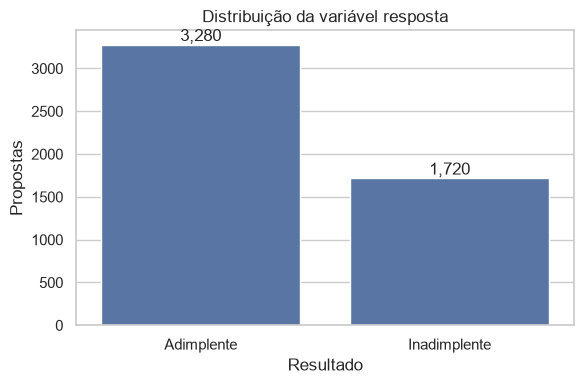

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
contagem_alvo = bruto["inadimplente"].map({0: "Adimplente", 1: "Inadimplente"}).value_counts()
sns.barplot(x=contagem_alvo.index, y=contagem_alvo.values, ax=ax)
ax.set(title="Distribuição da variável resposta", xlabel="Resultado", ylabel="Propostas")
for i, value in enumerate(contagem_alvo.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 3. Limpeza, tratamento e engenharia de atributos

Decisões aplicadas:

- espaços extras em categorias são removidos;
- idades acima de 100 são corrigidas apenas quando são exatamente dez vezes uma idade plausível;
- tempos de emprego acima do domínio observado de 30 anos são marcados como ausentes, sem adivinhação;
- duplicatas exatas são removidas;
- a razão `valor_solicitado / renda_mensal` representa o comprometimento relativo da renda.

A imputação do tempo de emprego não é feita globalmente: durante a modelagem, a mediana será aprendida apenas no treino dentro do pipeline. Isso evita vazamento de informação.

In [5]:
df = tratar_dados(bruto)
df.to_csv(PROJECT_DIR / "dataset_tratado.csv", index=False)

resumo_tratamento = pd.DataFrame({
    "antes": [len(bruto), bruto["estado"].nunique(), bruto.duplicated().sum(), (bruto["idade"] > 100).sum()],
    "depois": [len(df), df["estado"].nunique(), df.duplicated().sum(), df["idade"].between(18, 75).all()],
}, index=["linhas", "estados_distintos", "duplicatas", "idade_corrigida"])
print(f"Dimensões após tratamento: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Ausências criadas por valores inválidos: {df.isna().sum().sum()}")
display(resumo_tratamento)
display(df.isna().sum().rename("ausentes").to_frame())

Dimensões após tratamento: 4,981 linhas x 12 colunas
Ausências criadas por valores inválidos: 7


,antes,depois
linhas,5000,4981
estados_distintos,85,27
duplicatas,19,0
idade_corrigida,15,True


,ausentes
idade,0
estado,0
escolaridade,0
renda_mensal,0
tempo_emprego_anos,7
score_credito,0
valor_solicitado,0
prazo_meses,0
finalidade,0
dividas_ativas,0


In [6]:
numericas_eda = [
    "idade", "renda_mensal", "tempo_emprego_anos", "score_credito",
    "valor_solicitado", "prazo_meses", "dividas_ativas", "razao_emprestimo_renda",
]
display(df[numericas_eda].describe().T.round(2))
assert df["idade"].between(18, 75).all()
assert df["estado"].nunique() == 27
assert df.duplicated().sum() == 0
assert df["razao_emprestimo_renda"].notna().all()

,count,mean,std,min,25%,50%,75%,max
idade,"4,981.000",46.421,16.791,18.000,32.000,46.000,61.000,75.000
renda_mensal,"4,981.000","5,228.976","3,970.245",100.000,"2,698.380","4,145.870","6,458.740","44,814.190"
tempo_emprego_anos,"4,974.000",12.592,7.291,1.000,6.000,13.000,19.000,30.000
score_credito,"4,981.000",652.461,84.804,335.000,594.000,653.000,710.000,850.000
valor_solicitado,"4,981.000","14,260.293","8,267.027","1,721.480","8,466.240","12,363.960","17,763.210","50,000.000"
prazo_meses,"4,981.000",29.913,15.487,6.000,18.000,24.000,36.000,60.000
dividas_ativas,"4,981.000",1.900,1.864,0.000,0.000,1.000,3.000,7.000
razao_emprestimo_renda,"4,981.000",4.257,5.604,0.130,1.667,2.963,5.273,200.012


## 4. Análise exploratória

As comparações abaixo mostram associação com a resposta. Elas não devem ser interpretadas como causalidade.

In [7]:
variaveis_comparativas = ["score_credito", "renda_mensal", "dividas_ativas", "razao_emprestimo_renda", "valor_solicitado"]
comparativos = []
for coluna in variaveis_comparativas:
    auxiliar = df[[coluna, "inadimplente"]].copy()
    auxiliar["faixa"] = pd.qcut(auxiliar[coluna], 4, duplicates="drop")
    tabela = auxiliar.groupby("faixa", observed=True)["inadimplente"].agg(["count", "mean"]).reset_index()
    tabela.insert(0, "variavel", coluna)
    comparativos.append(tabela)
comparativos_df = pd.concat(comparativos, ignore_index=True)
comparativos_df["mean"] = comparativos_df["mean"].map(lambda value: f"{value:.1%}")
display(comparativos_df)

,variavel,faixa,count,mean
0,score_credito,"(334.999, 594.0]",1258,54.4%
1,score_credito,"(594.0, 653.0]",1253,37.8%
2,score_credito,"(653.0, 710.0]",1231,28.7%
3,score_credito,"(710.0, 850.0]",1239,16.5%
4,renda_mensal,"(99.999, 2698.38]",1246,50.8%
5,renda_mensal,"(2698.38, 4145.87]",1245,36.2%
6,renda_mensal,"(4145.87, 6458.74]",1245,28.7%
7,renda_mensal,"(6458.74, 44814.19]",1245,22.0%
8,dividas_ativas,"(-0.001, 1.0]",2509,27.3%
9,dividas_ativas,"(1.0, 3.0]",1474,37.3%


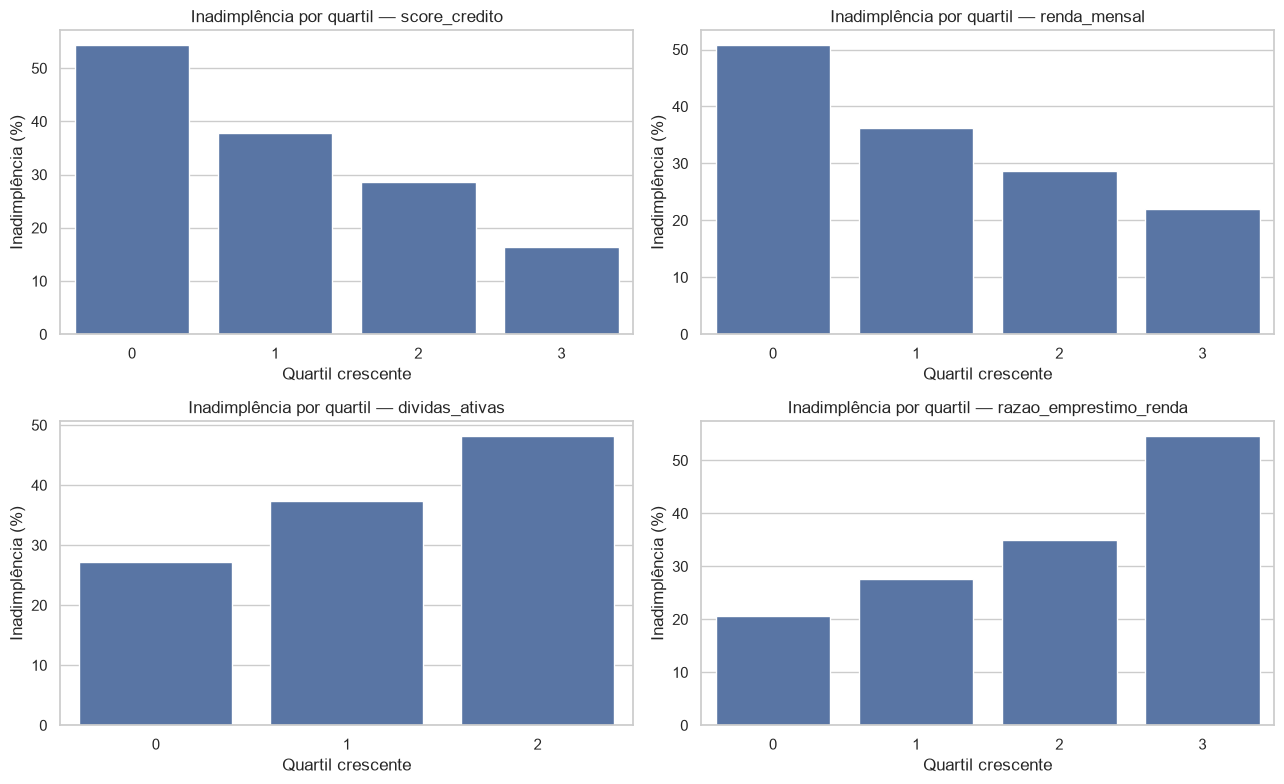

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, coluna in zip(axes.flat, ["score_credito", "renda_mensal", "dividas_ativas", "razao_emprestimo_renda"]):
    auxiliar = df[[coluna, "inadimplente"]].copy()
    auxiliar["faixa"] = pd.qcut(auxiliar[coluna], 4, duplicates="drop")
    taxas = auxiliar.groupby("faixa", observed=True)["inadimplente"].mean().mul(100)
    sns.barplot(x=np.arange(len(taxas)), y=taxas.values, ax=ax)
    ax.set(title=f"Inadimplência por quartil — {coluna}", xlabel="Quartil crescente", ylabel="Inadimplência (%)")
plt.tight_layout()
plt.show()

In [9]:
for coluna in ["escolaridade", "finalidade", "prazo_meses"]:
    tabela = df.groupby(coluna, observed=True)["inadimplente"].agg(quantidade="size", taxa="mean").sort_values("taxa", ascending=False)
    tabela["taxa"] = tabela["taxa"].map(lambda value: f"{value:.1%}")
    print()
    print(coluna)
    display(tabela)


escolaridade


,quantidade,taxa
escolaridade,,
Ensino Médio,2050,36.0%
Pós-graduação,589,33.6%
Ensino Superior,1932,33.4%
Ensino Fundamental,410,32.2%



finalidade


,quantidade,taxa
finalidade,,
Saúde,608,37.5%
Reforma,1112,34.9%
Veículo,1123,34.5%
Outros,939,33.8%
Educação,706,33.3%
Viagem,493,32.5%



prazo_meses


,quantidade,taxa
prazo_meses,,
6,292,54.5%
12,688,40.1%
18,649,36.7%
24,1010,34.9%
60,483,31.3%
48,597,30.3%
36,1262,28.4%


### Principais leituras exploratórias

- O quartil inferior de `score_credito` concentra mais inadimplência do que o quartil superior.
- Menor renda e maior quantidade de dívidas ativas estão associados a taxas maiores.
- A razão entre valor solicitado e renda é uma variável derivada útil: ela compara o pedido com a capacidade declarada, em vez de olhar apenas o valor absoluto.
- O prazo de 6 meses apresenta taxa elevada neste conjunto; por ser um padrão observacional, deve ser validado pelo modelo e não usado isoladamente para decisão.

## 5. Preparação para modelagem

Será usado um `Pipeline` para impedir vazamento: imputação, padronização e codificação são ajustadas exclusivamente no treino. A divisão é estratificada para manter a proporção de inadimplentes.

In [10]:
alvo = "inadimplente"
features_originais = [coluna for coluna in colunas_esperadas if coluna != alvo]
features_com_derivada = features_originais + ["razao_emprestimo_renda"]
features_sem_estado = [coluna for coluna in features_com_derivada if coluna != "estado"]
feature_sets = {
    "M1 — originais": features_originais,
    "M2 — originais + razão": features_com_derivada,
    "M3 — sem estado + razão": features_sem_estado,
}

X = df[features_com_derivada]
y = df[alvo]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Treino: {X_train.shape[0]:,} | Teste: {X_test.shape[0]:,}")
print(f"Taxa de inadimplência no treino: {y_train.mean():.1%}")
print(f"Taxa de inadimplência no teste: {y_test.mean():.1%}")
display(pd.DataFrame({nome: pd.Series(colunas) for nome, colunas in feature_sets.items()}))

Treino: 3,984 | Teste: 997
Taxa de inadimplência no treino: 34.4%
Taxa de inadimplência no teste: 34.4%


,M1 — originais,M2 — originais + razão,M3 — sem estado + razão
0,idade,idade,idade
1,estado,estado,escolaridade
2,escolaridade,escolaridade,renda_mensal
3,renda_mensal,renda_mensal,tempo_emprego_anos
4,tempo_emprego_anos,tempo_emprego_anos,score_credito
5,score_credito,score_credito,valor_solicitado
6,valor_solicitado,valor_solicitado,prazo_meses
7,prazo_meses,prazo_meses,finalidade
8,finalidade,finalidade,dividas_ativas
9,dividas_ativas,dividas_ativas,razao_emprestimo_renda


In [11]:
def criar_pipeline(features):
    numericas = [coluna for coluna in features if coluna not in ["estado", "escolaridade", "finalidade"]]
    categoricas = [coluna for coluna in features if coluna in ["estado", "escolaridade", "finalidade"]]
    pre_processamento = ColumnTransformer(
        transformers=[
            ("numericas", Pipeline([
                ("imputacao", SimpleImputer(strategy="median")),
                ("escala", StandardScaler()),
            ]), numericas),
            ("categoricas", Pipeline([
                ("imputacao", SimpleImputer(strategy="most_frequent")),
                ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), categoricas),
        ],
        remainder="drop",
    )
    return Pipeline([
        ("pre_processamento", pre_processamento),
        ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
}

cv_linhas = []
pipelines = {}
for nome, features in feature_sets.items():
    pipeline = criar_pipeline(features)
    pipelines[nome] = pipeline
    resultado = cross_validate(pipeline, X_train[features], y_train, cv=cv, scoring=metricas, n_jobs=1)
    linha = {"modelo": nome}
    for metrica in metricas:
        linha[f"{metrica}_media"] = resultado[f"test_{metrica}"].mean()
        linha[f"{metrica}_desvio"] = resultado[f"test_{metrica}"].std()
    cv_linhas.append(linha)

cv_resultados = pd.DataFrame(cv_linhas).sort_values("pr_auc_media", ascending=False)
display(cv_resultados.round(3))

,modelo,roc_auc_media,roc_auc_desvio,pr_auc_media,pr_auc_desvio,recall_media,recall_desvio,precision_media,precision_desvio,f1_media,f1_desvio,balanced_accuracy_media,balanced_accuracy_desvio
2,M3 — sem estado + razão,0.777,0.012,0.654,0.031,0.463,0.010,0.660,0.025,0.544,0.014,0.669,0.010
1,M2 — originais + razão,0.771,0.011,0.648,0.030,0.467,0.022,0.658,0.026,0.546,0.023,0.670,0.014
0,M1 — originais,0.764,0.012,0.633,0.025,0.462,0.023,0.643,0.028,0.538,0.023,0.664,0.015


## 6. Modelagem e avaliação no conjunto de teste

O baseline prevê sempre a classe majoritária. Ele é necessário para verificar se a Regressão Logística aprende sinal além de uma regra ingênua. O teste é usado uma única vez para estimar o desempenho final após a comparação por validação cruzada no treino.

In [12]:
def calcular_metricas(y_verdadeiro, y_predito, probabilidade):
    return {
        "accuracy": accuracy_score(y_verdadeiro, y_predito),
        "roc_auc": roc_auc_score(y_verdadeiro, probabilidade),
        "pr_auc": average_precision_score(y_verdadeiro, probabilidade),
        "recall": recall_score(y_verdadeiro, y_predito, zero_division=0),
        "precision": precision_score(y_verdadeiro, y_predito, zero_division=0),
        "f1": f1_score(y_verdadeiro, y_predito, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_verdadeiro, y_predito),
    }

modelos_teste = {}
metricas_teste = []
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:, 1]
metricas_teste.append({"modelo": "Baseline — classe majoritária", **calcular_metricas(y_test, baseline_pred, baseline_prob)})

for nome, pipeline in pipelines.items():
    features = feature_sets[nome]
    pipeline.fit(X_train[features], y_train)
    modelos_teste[nome] = pipeline
    pred = pipeline.predict(X_test[features])
    prob = pipeline.predict_proba(X_test[features])[:, 1]
    metricas_teste.append({"modelo": nome, **calcular_metricas(y_test, pred, prob)})

teste_resultados = pd.DataFrame(metricas_teste).sort_values("pr_auc", ascending=False)
display(teste_resultados.round(3))

,modelo,accuracy,roc_auc,pr_auc,recall,precision,f1,balanced_accuracy
3,M3 — sem estado + razão,0.730,0.771,0.648,0.449,0.658,0.534,0.663
2,M2 — originais + razão,0.732,0.766,0.643,0.458,0.660,0.540,0.667
1,M1 — originais,0.727,0.760,0.633,0.449,0.650,0.531,0.661
0,Baseline — classe majoritária,0.656,0.500,0.344,0.000,0.000,0.000,0.500


Modelo selecionado pela PR-AUC média da validação cruzada: M3 — sem estado + razão
Variáveis utilizadas: idade, escolaridade, renda_mensal, tempo_emprego_anos, score_credito, valor_solicitado, prazo_meses, finalidade, dividas_ativas, razao_emprestimo_renda

Relatório de classificação no teste:
              precision    recall  f1-score   support

  Adimplente       0.75      0.88      0.81       654
Inadimplente       0.66      0.45      0.53       343

    accuracy                           0.73       997
   macro avg       0.71      0.66      0.67       997
weighted avg       0.72      0.73      0.72       997



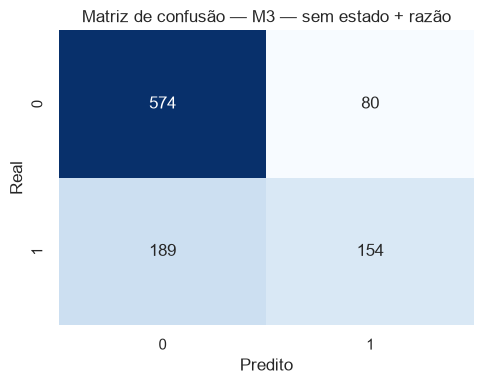

In [13]:
melhor_modelo_nome = cv_resultados.iloc[0]["modelo"]
melhor_modelo = modelos_teste[melhor_modelo_nome]
melhores_features = feature_sets[melhor_modelo_nome]
melhor_pred = melhor_modelo.predict(X_test[melhores_features])
melhor_prob = melhor_modelo.predict_proba(X_test[melhores_features])[:, 1]

print(f"Modelo selecionado pela PR-AUC média da validação cruzada: {melhor_modelo_nome}")
print(f"Variáveis utilizadas: {', '.join(melhores_features)}")
print()
print("Relatório de classificação no teste:")
print(classification_report(y_test, melhor_pred, target_names=["Adimplente", "Inadimplente"], zero_division=0))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, melhor_pred), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title=f"Matriz de confusão — {melhor_modelo_nome}", xlabel="Predito", ylabel="Real")
plt.tight_layout()
plt.show()

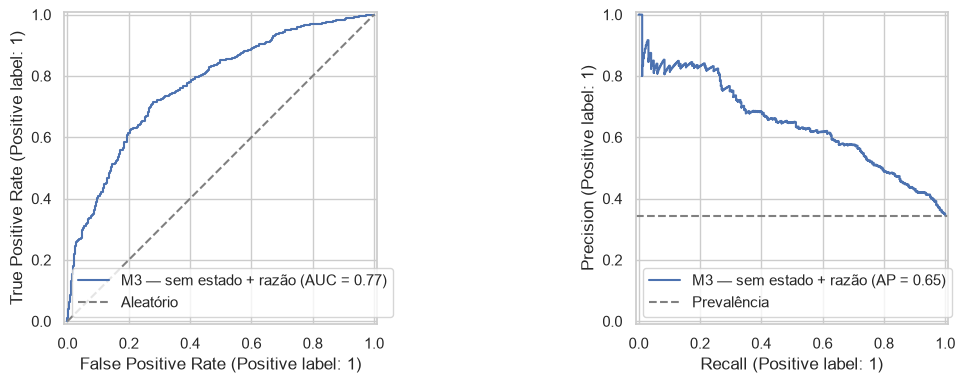

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_test, melhor_prob, ax=axes[0], name=melhor_modelo_nome)
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
axes[0].legend()
PrecisionRecallDisplay.from_predictions(y_test, melhor_prob, ax=axes[1], name=melhor_modelo_nome)
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Prevalência")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Interpretação da Regressão Logística

Para variáveis numéricas, os coeficientes correspondem ao efeito de aproximadamente um desvio-padrão, pois houve padronização. Para categorias, cada coeficiente é relativo à categoria de referência criada pelo one-hot encoding. `odds_ratio > 1` indica associação com aumento das chances estimadas de inadimplência; `odds_ratio < 1` indica redução. Associação não implica causalidade.

In [15]:
pre_processamento = melhor_modelo.named_steps["pre_processamento"]
classificador = melhor_modelo.named_steps["modelo"]
nomes_atributos = pre_processamento.get_feature_names_out()
coeficientes = classificador.coef_[0]
coeficientes_df = pd.DataFrame({
    "atributo": nomes_atributos,
    "coeficiente": coeficientes,
    "odds_ratio": np.exp(coeficientes),
})

print("Maiores associações positivas:")
display(coeficientes_df.sort_values("coeficiente", ascending=False).head(10).round(3))
print("Maiores associações negativas:")
display(coeficientes_df.sort_values("coeficiente").head(10).round(3))

Maiores associações positivas:


,atributo,coeficiente,odds_ratio
7,numericas__razao_emprestimo_renda,0.540,1.716
6,numericas__dividas_ativas,0.450,1.568
4,numericas__valor_solicitado,0.162,1.176
15,categoricas__finalidade_Saúde,0.054,1.055
9,categoricas__escolaridade_Ensino Médio,-0.043,0.958
11,categoricas__escolaridade_Pós-graduação,-0.064,0.938
13,categoricas__finalidade_Outros,-0.101,0.904
0,numericas__idade,-0.103,0.902
12,categoricas__finalidade_Educação,-0.114,0.892
17,categoricas__finalidade_Viagem,-0.115,0.891


Maiores associações negativas:


,atributo,coeficiente,odds_ratio
3,numericas__score_credito,-0.790,0.454
1,numericas__renda_mensal,-0.380,0.684
2,numericas__tempo_emprego_anos,-0.253,0.776
8,categoricas__escolaridade_Ensino Fundamental,-0.253,0.776
5,numericas__prazo_meses,-0.240,0.787
10,categoricas__escolaridade_Ensino Superior,-0.203,0.816
14,categoricas__finalidade_Reforma,-0.155,0.857
16,categoricas__finalidade_Veículo,-0.133,0.876
17,categoricas__finalidade_Viagem,-0.115,0.891
12,categoricas__finalidade_Educação,-0.114,0.892


## 8. Conclusão, limitações e cuidados

### Conclusão

A análise compara um baseline simples com versões da Regressão Logística e verifica o ganho da variável derivada de comprometimento da renda. A escolha final deve considerar especialmente PR-AUC e recall da classe inadimplente, pois perder um caso de risco pode ser mais relevante do que maximizar a acurácia geral.

### Limitações

- Os dados são sintéticos e não comprovam desempenho em uma carteira real.
- Não há dimensão temporal para validar estabilidade e drift.
- O limiar padrão de 0,5 não representa necessariamente o custo real de falso positivo e falso negativo.
- `estado` pode funcionar como proxy geográfico; por isso foi comparado com uma versão sem essa variável.
- O modelo identifica associação preditiva, não causalidade.

Em produção seriam necessários validação temporal, análise de fairness, definição de custos de decisão, monitoramento de drift, governança e revisão humana.

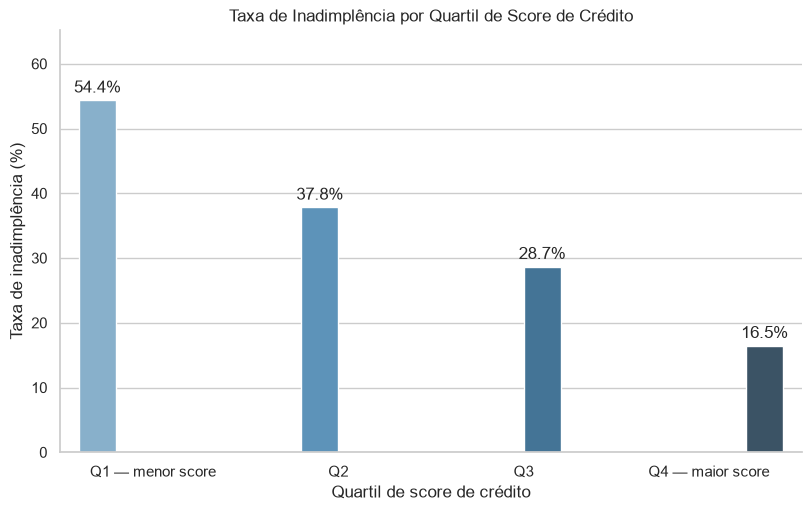

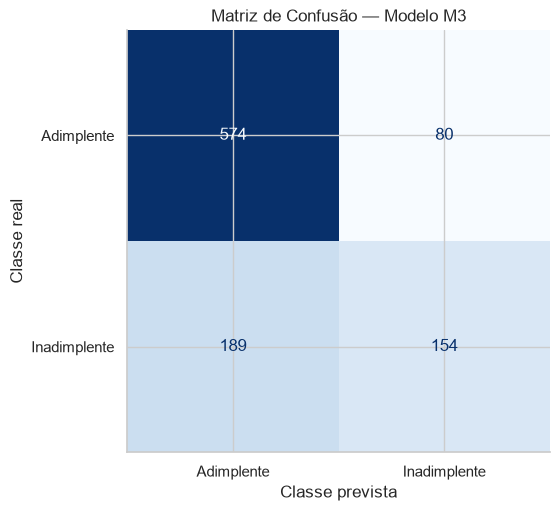

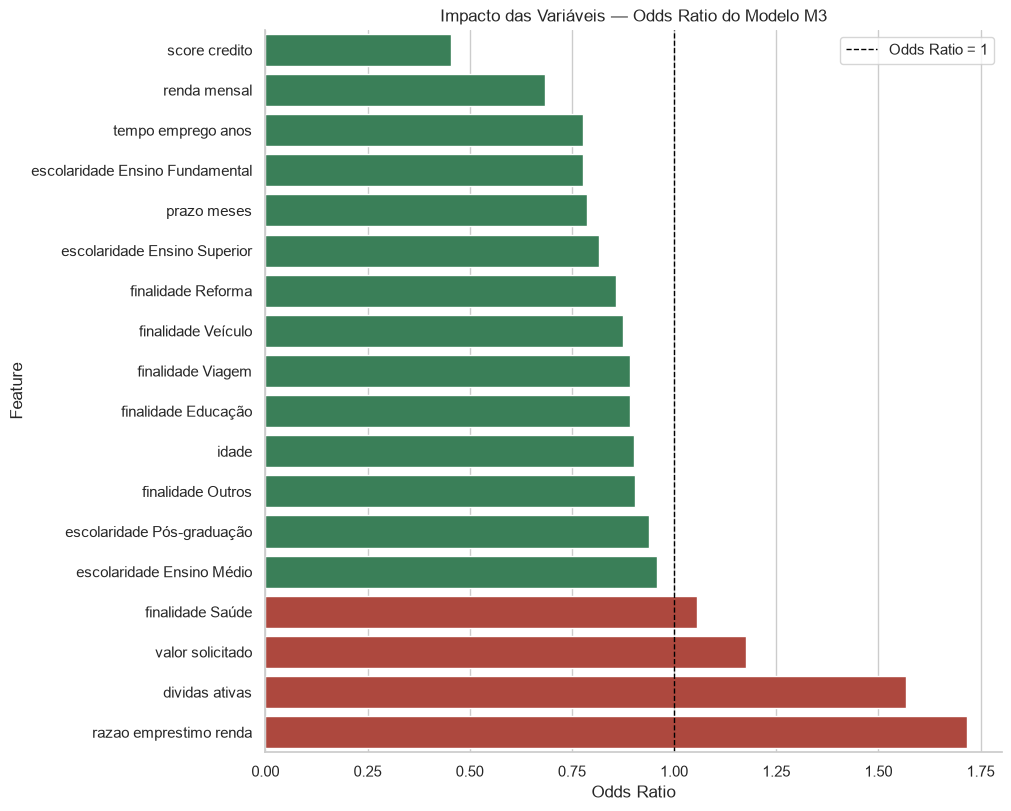

Imagens salvas em: D:\lab\Analise_Credito\desafios\analise-credito\imagens


In [16]:
import os

IMAGENS_DIR = PROJECT_DIR / "imagens"
os.makedirs(IMAGENS_DIR, exist_ok=True)

# Gráfico 1 — taxa de inadimplência por quartil de score.
score_quartis = df[["score_credito", "inadimplente"]].copy()
score_quartis["quartil_score"] = pd.qcut(
    score_quartis["score_credito"],
    q=4,
    labels=["Q1 — menor score", "Q2", "Q3", "Q4 — maior score"],
)
taxa_score = (
    score_quartis.groupby("quartil_score", observed=True)["inadimplente"]
    .mean()
    .mul(100)
    .reset_index(name="taxa_inadimplencia")
)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
sns.barplot(
    data=taxa_score,
    x="quartil_score",
    y="taxa_inadimplencia",
    hue="quartil_score",
    palette="Blues_d",
    legend=False,
    ax=ax,
)
ax.set_title("Taxa de Inadimplência por Quartil de Score de Crédito")
ax.set_xlabel("Quartil de score de crédito")
ax.set_ylabel("Taxa de inadimplência (%)")
ax.set_ylim(0, max(taxa_score["taxa_inadimplencia"]) * 1.2)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "taxa_inadimplencia_score.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Gráfico 2 — matriz de confusão do M3 no conjunto de teste.
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    melhor_pred,
    display_labels=["Adimplente", "Inadimplente"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=ax,
)
ax.set_title("Matriz de Confusão — Modelo M3")
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "matriz_confusao_m3.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Gráfico 3 — odds ratios do M3, com cores condicionais.
odds_plot = coeficientes_df.copy()
odds_plot["feature"] = (
    odds_plot["atributo"]
    .str.replace(r"^(numericas|categoricas)__", "", regex=True)
    .str.replace("_", " ")
)
odds_plot["cor"] = np.where(odds_plot["odds_ratio"] > 1, "red", "green")
odds_plot = odds_plot.sort_values("odds_ratio", ascending=True)
paleta_odds = {"red": "#C0392B", "green": "#2E8B57"}

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
sns.barplot(
    data=odds_plot,
    x="odds_ratio",
    y="feature",
    hue="cor",
    palette=paleta_odds,
    dodge=False,
    legend=False,
    ax=ax,
)
ax.axvline(1, color="black", linewidth=1, linestyle="--", label="Odds Ratio = 1")
ax.set_title("Impacto das Variáveis — Odds Ratio do Modelo M3")
ax.set_xlabel("Odds Ratio")
ax.set_ylabel("Feature")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.savefig(IMAGENS_DIR / "odds_ratio_features.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Imagens salvas em: {IMAGENS_DIR.resolve()}")